In [1]:
import os
import pandas as pd
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
import seaborn as sns

c:\Users\juan_\AppData\Local\Programs\Python\Python310\lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.25.905) or chardet (7.6.0)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


In [3]:
# 1. Load clinical metadata
csv_path = r"C:\Users\juan_\Desktop\cv-medical\COBRE_Dataset\participants.tsv"
df = pd.read_csv(csv_path, sep='\t')

data_dir = r"C:\Users\juan_\Desktop\cv-medical\COBRE_Dataset"

# List to store physical image metrics extracted from each volume
image_metrics = []

In [4]:
print("--- Starting physical image metrics extraction ---")
for idx, row in df.iterrows():
    pid = row['participant_id']
    img_path = os.path.join(data_dir, pid, "anat", f"{pid}_T1w.nii.gz")
    
    if os.path.exists(img_path):
        try:
            # Load 3D NIfTI volume
            nii_img = nib.load(img_path)
            volume = nii_img.get_fdata()
            
            # Basic voxel intensity statistics
            mean_intensity = np.mean(volume)
            std_intensity = np.std(volume)
            
            # Brain volume proxy: Count voxels containing actual tissue 
            # (excluding background where intensity is close to zero)
            threshold = np.max(volume) * 0.05  # 5% of peak intensity as tissue threshold
            brain_voxel_count = np.sum(volume > threshold)
            
            image_metrics.append({
                'participant_id': pid,
                'mean_intensity': mean_intensity,
                'std_intensity': std_intensity,
                'brain_voxel_count': brain_voxel_count
            })
        except Exception as e:
            print(f"Error processing {pid}: {e}")

--- Starting physical image metrics extraction ---


In [5]:
# Convert extracted metrics to a Pandas DataFrame
df_images = pd.DataFrame(image_metrics)

# 2. Merge clinical metadata with physical image metrics
df_merged = pd.merge(df, df_images, on='participant_id', how='inner')
print(f"\nProcess completed successfully! Analyzed {len(df_merged)} 3D volumes.")


Process completed successfully! Analyzed 265 3D volumes.


In [6]:
# 3. Quick statistical check: Brain volume proxy across diagnostic groups
print("\n--- Average Brain Volume Proxy by Diagnosis ---")
volume_summary = df_merged.groupby('diagnosis')['brain_voxel_count'].agg(['mean', 'std', 'median'])
print(volume_summary.round(2))


--- Average Brain Volume Proxy by Diagnosis ---
                 mean        std     median
diagnosis                                  
ADHD       3118736.05  311907.02  3114707.0
BIPOLAR    3284086.18  381780.22  3293802.0
CONTROL    3194135.90  564979.07  3117366.0
SCHZ       3440985.76  389877.74  3417538.0


C:\Users\juan_\AppData\Local\Temp\ipykernel_15584\3470680160.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='diagnosis', y='brain_voxel_count', data=df_merged, palette='Set2', ax=axes[0])
C:\Users\juan_\AppData\Local\Temp\ipykernel_15584\3470680160.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='diagnosis', y='mean_intensity', data=df_merged, palette='Set3', ax=axes[1])


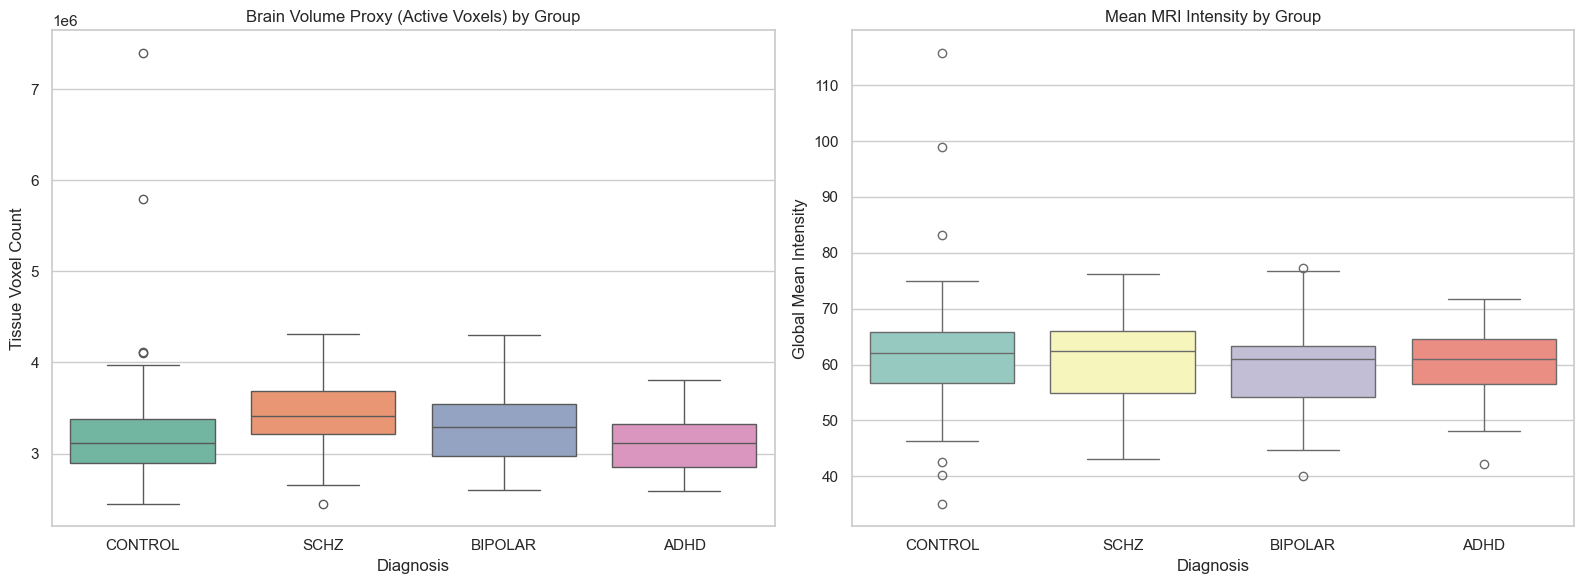

In [ ]:
# ==========================================
# 4. VISUALIZATION OF PHYSICAL METRICS
# ==========================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Brain Volume Proxy vs Diagnosis for each 3D volume
sns.boxplot(x='diagnosis', y='brain_voxel_count', data=df_merged, palette='Set2', ax=axes[0])
axes[0].set_title('Brain Volume Proxy (Active Voxels) by Group')
axes[0].set_xlabel('Diagnosis')
axes[0].set_ylabel('Tissue Voxel Count')

# Plot 2: Mean Intensity vs Diagnosis for each 3D volume
sns.boxplot(x='diagnosis', y='mean_intensity', data=df_merged, palette='Set3', ax=axes[1])
axes[1].set_title('Mean MRI Intensity by Group')
axes[1].set_xlabel('Diagnosis')
axes[1].set_ylabel('Global Mean Intensity')

plt.tight_layout()
plt.show()